# Nairobi Heat Exposure ABM — Exploratory Notebook

End-to-end walkthrough of the pipeline:
**Phase 1 (data)** → **Phase 2 (simulation)** → **Results**

**Pre-requisites**
```bash
pip install -e ".[dev]"   # from project root
pip install jupyter matplotlib
```
Internet access is required on first run to download the OSM walk network and amenity index.
WorldPop and heat TIFs are optional — synthetic fallbacks are used if the files are absent.

### Data sources

| Input | Source | What it provides | Fallback if absent |
|---|---|---|---|
| Walk network | OpenStreetMap, via `osmnx.graph_from_bbox(network_type="walk")` (Overpass API) | Every walkable way in the study bbox as a `networkx.MultiDiGraph`: nodes = intersections/dead-ends (`x`/`y` = lon/lat, EPSG:4326), edges = street segments (`length` in metres, `travel_time` in seconds, `geometry`) | None &mdash; always a live download on first run; cached to `data/raw/graph.graphml` after that |
| Population | [WorldPop](https://hub.worldpop.org) 100 m gridded population count for Kenya, clipped to the study bbox | A raster of people-per-100m-cell, used to weight where agents "live" (spawn) | Uniform synthetic raster if `data/raw/worldpop_nairobi.tif` is absent |
| Amenities (POIs) | OpenStreetMap, via `osmnx.features_from_bbox()` with per-category tag filters (`school`, `shop`/`marketplace`/`supermarket`, `health`, `place_of_worship`/`community_centre`/`library`) | Point/polygon locations for schools, shops, health facilities, and other destinations, snapped to the nearest graph node | None currently &mdash; an OSM fetch failure for a category silently yields an empty list for that category, not a hard error |
| Heat surface | WRI Thermal Comfort Mapping (TCM) UTCI tiles &mdash; tiled UTM GeoTIFFs, one mosaic per hour-of-day (`UTCI_<year>_<day-of-year>_<HHMM>D.tif`) | Universal Thermal Comfort Index (°C-equivalent) at several times of day, reprojected to EPSG:4326 | Synthetic diurnal surface with a Gaussian urban-heat-island bump if no real tiles are present in `data/raw/heat/` &mdash; **this is the only data source not yet available for Nairobi**; real tiles are still pending in the WRI TCM S3 bucket |

The study area is a single bounding box defined in `config.yaml` (`south=-1.444, west=36.649, north=-1.163, east=37.104` &mdash; greater Nairobi), so every source above is clipped/downloaded to that same extent.

In [1]:
import os
import sys
from pathlib import Path

# Allow imports from project root without pip install
ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Anaconda often sets PROJ_DATA/GDAL_DATA as user-level env vars pointing at its own
# (incompatible) PROJ/GDAL install. That leaks into this .venv kernel and breaks
# rasterio's CRS lookups ("DATABASE.LAYOUT.VERSION.MINOR" errors). Force rasterio's
# own bundled data dirs instead, before any geospatial library touches PROJ/GDAL.
_rasterio_proj_data = ROOT / ".venv" / "Lib" / "site-packages" / "rasterio" / "proj_data"
_rasterio_gdal_data = ROOT / ".venv" / "Lib" / "site-packages" / "rasterio" / "gdal_data"
if _rasterio_proj_data.exists():
    os.environ["PROJ_DATA"] = str(_rasterio_proj_data)
    os.environ.pop("PROJ_LIB", None)
if _rasterio_gdal_data.exists():
    os.environ["GDAL_DATA"] = str(_rasterio_gdal_data)

import numpy as np
import matplotlib.pyplot as plt
import yaml

with open(ROOT / "config.yaml") as f:
    cfg = yaml.safe_load(f)

b = cfg["bbox"]
BBOX = (b["south"], b["west"], b["north"], b["east"])
SIM  = cfg["simulation"]
PATHS = cfg["paths"]

RAW = ROOT / "data" / "raw"
RAW.mkdir(parents=True, exist_ok=True)

print(f"Study bbox : {BBOX}")
print(f"Simulation : {SIM}")

Study bbox : (-1.444, 36.649, -1.163, 37.104)
Simulation : {'start_hour': 6, 'end_hour': 20, 'timestep_seconds': 60, 'default_n_agents': 5000, 'default_seed': 42}


---
## Phase 1 — Data infrastructure
### 1.1  Walk network (OSM via osmnx)

In [2]:
import osmnx as ox
from nairobi_heat_abm.data.graph import build_graph

GRAPH_CACHE = ROOT / PATHS["graph_cache"]
GRAPH_CACHE.parent.mkdir(parents=True, exist_ok=True)

FORCE_REBUILD_GRAPH = False  # set True to re-download even if a cache file exists

if GRAPH_CACHE.exists() and not FORCE_REBUILD_GRAPH:
    print(f"Cache hit: loading walk network from {GRAPH_CACHE} …")
else:
    print(f"Cache miss: downloading walk network from OSM (may take ~60 s) …")

G = build_graph(BBOX, cache_path=GRAPH_CACHE, force_rebuild=FORCE_REBUILD_GRAPH)
print(f"Graph ready: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges")

Cache hit: loading walk network from C:\Users\tgwon\wri\ride\data\raw\graph.graphml …
Graph ready: 120,077 nodes, 291,588 edges


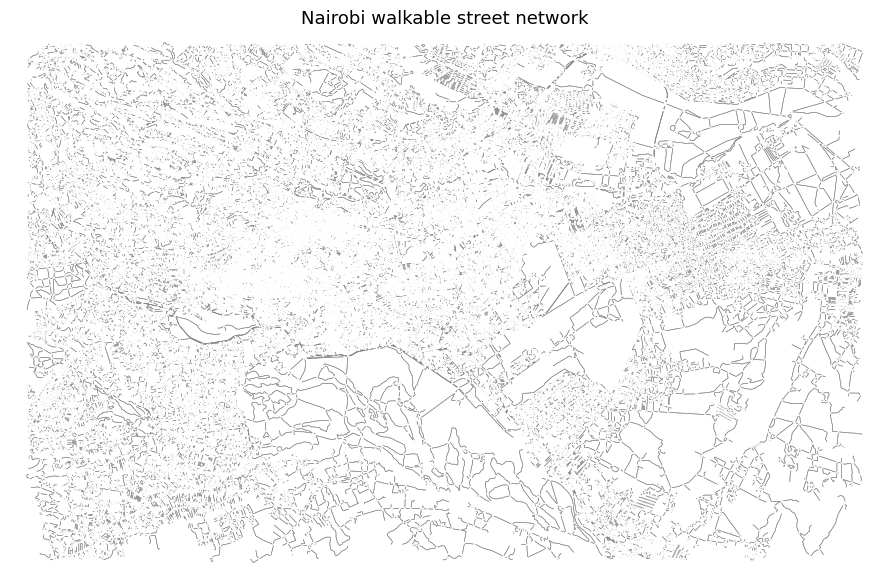

In [3]:
fig, ax = ox.plot_graph(
    G, figsize=(9, 7), show=False, close=False,
    node_size=2, edge_linewidth=0.4, edge_color="#888", bgcolor="white",
)
ax.set_title("Nairobi walkable street network", fontsize=13)
plt.tight_layout()
plt.show()

### 1.2  Population raster
Place `worldpop_nairobi.tif` in `data/raw/` (100 m WorldPop grid for Kenya).  
A uniform synthetic fallback is used automatically if the file is absent.

In [4]:
import rasterio
import rasterio.transform
from nairobi_heat_abm.data.population import load_population_raster, sample_spawn_nodes

WP_PATH = ROOT / PATHS["worldpop_tif"]

if WP_PATH.exists():
    print(f"Cache hit: loading WorldPop raster from {WP_PATH} …")
    density, pop_transform = load_population_raster(str(WP_PATH), BBOX)
    print(f"Loaded WorldPop raster: {density.shape}")
else:
    print(f"Cache miss: no WorldPop TIF at {WP_PATH} — generating synthetic density …")
    south, west, north, east = BBOX
    rows, cols = 60, 60
    pop_transform = rasterio.transform.from_bounds(west, south, east, north, cols, rows)
    # Mild density gradient: denser toward the city centre
    yy = np.linspace(0, 1, rows)[:, None]
    xx = np.linspace(0, 1, cols)[None, :]
    density = (1.0 + 2.0 * np.exp(-((xx - 0.45)**2 + (yy - 0.55)**2) / 0.05)).astype(np.float32)

    # Save to disk so simulation.run() can load it via load_population_raster,
    # and so the next notebook run hits the cache branch above instead of regenerating.
    WP_PATH.parent.mkdir(parents=True, exist_ok=True)
    with rasterio.open(
        WP_PATH, "w", driver="GTiff",
        height=rows, width=cols, count=1,
        dtype=np.float32, crs="EPSG:4326", transform=pop_transform,
    ) as dst:
        dst.write(density[np.newaxis, :, :])
    print(f"Saved synthetic WorldPop to {WP_PATH} (will be reused on next run)")

print(f"Density array: shape={density.shape}, range=[{np.nanmin(density):.1f}, {np.nanmax(density):.1f}]")

Cache hit: loading WorldPop raster from C:\Users\tgwon\wri\ride\data\raw\worldpop_nairobi.tif …
Loaded WorldPop raster: (313, 506)
Density array: shape=(313, 506), range=[0.0, 943.4]


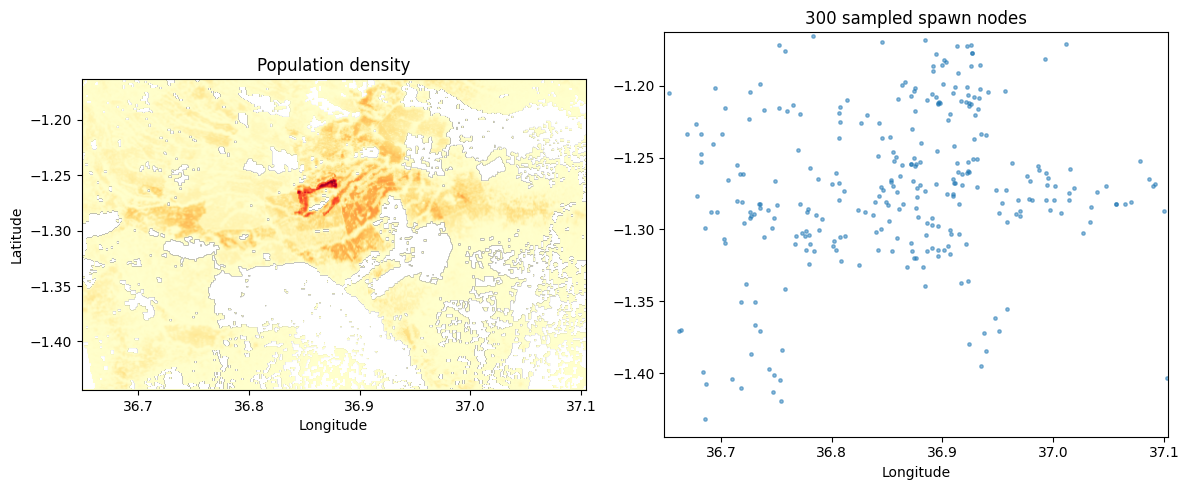

In [5]:
rng = np.random.default_rng(42)
spawn_nodes = sample_spawn_nodes(density, pop_transform, G, n_agents=300, rng=rng)
spawn_xs = [G.nodes[n]["x"] for n in spawn_nodes]
spawn_ys = [G.nodes[n]["y"] for n in spawn_nodes]

south, west, north, east = BBOX
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(
    density, extent=[west, east, south, north],
    origin="upper", cmap="YlOrRd",
)
axes[0].set_title("Population density")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")

axes[1].scatter(spawn_xs, spawn_ys, s=6, alpha=0.5, c="tab:blue")
axes[1].set_xlim(west, east); axes[1].set_ylim(south, north)
axes[1].set_title("300 sampled spawn nodes")
axes[1].set_xlabel("Longitude")

plt.tight_layout()
plt.show()

### 1.3  Heat surface
Place a multi-band GeoTIFF (one band per simulated hour) in `data/raw/heat/`, or a directory of single-band TIFs.  
A synthetic diurnal surface with an urban heat-island gradient is used automatically if no files are present.

In [ ]:
from nairobi_heat_abm.data.heat import load_heat_surface, HeatSurface

HEAT_DIR  = ROOT / PATHS["heat_dir"]
HEAT_TIFS = list(HEAT_DIR.glob("*.tif")) + list(HEAT_DIR.glob("*.tiff")) if HEAT_DIR.exists() else []

if HEAT_TIFS:
    surface = load_heat_surface(HEAT_DIR)
    print(f"Loaded heat surface from {HEAT_DIR}: shape={surface.array.shape}, hours={surface.hours}")
else:
    print("No heat TIFs found — building synthetic diurnal surface …")
    south, west, north, east = BBOX
    rows, cols = 60, 60
    htransform = rasterio.transform.from_bounds(west, south, east, north, cols, rows)
    hours = [6, 9, 12, 15, 18]
    base_temps = [26.0, 30.0, 35.0, 33.0, 29.0]  # °C at each hour

    # Urban heat-island: ~4 °C hotter in the centre
    yy = np.linspace(0, 1, rows)[:, None]
    xx = np.linspace(0, 1, cols)[None, :]
    uhi = 4.0 * np.exp(-((xx - 0.45)**2 + (yy - 0.55)**2) / 0.08)

    rng_h = np.random.default_rng(0)
    bands = [
        (t + uhi + rng_h.normal(0, 0.3, (rows, cols))).astype(np.float32)
        for t in base_temps
    ]
    surface = HeatSurface(
        array=np.stack(bands),
        transform=htransform,
        hours=hours,
        crs="EPSG:4326",
        name="synthetic",
    )
    print(f"Synthetic surface: shape={surface.array.shape}, hours={surface.hours}")

In [ ]:
# Visualise temperature at each simulated hour
n_h = len(surface.hours)
fig, axes = plt.subplots(1, n_h, figsize=(3.5 * n_h, 4), sharey=True)
if n_h == 1:
    axes = [axes]

vmin, vmax = surface.array.min(), surface.array.max()
south, west, north, east = BBOX

for ax, band, hour in zip(axes, surface.array, surface.hours):
    im = ax.imshow(
        band, extent=[west, east, south, north],
        origin="upper", cmap="RdYlBu_r", vmin=vmin, vmax=vmax,
    )
    ax.set_title(f"{hour:02d}:00")
    ax.set_xlabel("Lon")

axes[0].set_ylabel("Lat")
fig.colorbar(im, ax=axes, label="Temperature (°C)", shrink=0.8)
fig.suptitle(f"Heat surface — {surface.name}", y=1.02)
plt.tight_layout()
plt.show()

### 1.4  Amenity index (OSM POIs)
Fetches schools, shops, health facilities, and other POIs and snaps them to the nearest walkable node.  
Result is cached to `data/raw/amenities.json`.

In [ ]:
from nairobi_heat_abm.data.amenities import build_amenity_index

AMENITY_CACHE = ROOT / PATHS["amenity_cache"]
FORCE_REBUILD_AMENITIES = False  # set True to re-fetch even if a cache file exists

if AMENITY_CACHE.exists() and not FORCE_REBUILD_AMENITIES:
    print(f"Cache hit: loading amenity index from {AMENITY_CACHE} …")
else:
    print(f"Cache miss: fetching amenity index from OSM …")

amenities = build_amenity_index(BBOX, G, cache_path=AMENITY_CACHE, force_rebuild=FORCE_REBUILD_AMENITIES)

print("\nAmenity counts:")
for cat, nodes in amenities.items():
    print(f"  {cat:8s}: {len(nodes):4d} locations")

In [ ]:
# Spot-check: plot each amenity category on a scatter map
colours = {"school": "tab:blue", "shop": "tab:orange", "health": "tab:red", "other": "tab:green"}
south, west, north, east = BBOX

fig, ax = plt.subplots(figsize=(7, 7))
for cat, node_ids in amenities.items():
    if not node_ids:
        continue
    xs = [G.nodes[n]["x"] for n in node_ids if G.has_node(n)]
    ys = [G.nodes[n]["y"] for n in node_ids if G.has_node(n)]
    ax.scatter(xs, ys, s=8, alpha=0.6, c=colours[cat], label=cat)

ax.set_xlim(west, east); ax.set_ylim(south, north)
ax.set_title("OSM amenities snapped to walk network")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.legend(markerscale=2)
plt.tight_layout()
plt.show()

### How the pipeline represents the world

Everything downstream of Phase 1 loading is built on three plain data structures:

**The walk network** (`networkx.MultiDiGraph`, from `data/graph.py`)
- Nodes: `x`/`y` (lon/lat, EPSG:4326), `node_type` (`"intersection"`, or `"amenity"` once `build_amenity_index()` tags POI nodes).
- Edges: `length` (metres), `travel_time` (seconds, from OSM speed limits), `weight` (routing cost &mdash; currently equal to `travel_time`), `geometry`, and `edge_type` (only set for transit edges once GTFS is integrated &mdash; every current edge is implicitly a walk edge).
- Read-only after `build_graph()` returns it &mdash; nothing in the model layer mutates the graph at runtime.

**Agents** (`AgentPool`, `model/agent.py`) &mdash; columnar NumPy arrays, one row-index per agent, never per-agent Python objects:

| Field | dtype | Meaning |
|---|---|---|
| `edge_u`, `edge_v`, `edge_key` | int | The `(u, v, key)` MultiDiGraph edge the agent is currently on |
| `progress` | float32 | 0.0 (at `u`) &rarr; 1.0 (at `v`) along the current edge |
| `mode` | uint8 | 0 = walk, 1 = wait, 2 = transit |
| `trip_purpose` | uint8 | 0 = work, 1 = school, 2 = market, 3 = other |
| `active` | bool | `False` once the agent's trip is complete (or no route was found) |
| `heat_exposure_degC_min` | float32 | Running total of °C &times; minutes accumulated so far |
| `route_edges` / `route_index` | list / int32 | Per-agent list of `(u, v, key)` tuples from `assign_routes()`, and the agent's current position in that list |

**Heat surface** (`HeatSurface`, `data/heat.py`) &mdash; a `(n_hours, rows, cols)` array plus an affine `transform` and a list of `hours` (one band per simulated hour-of-day). `sample_temperature()` bilinearly interpolates this grid at an agent's interpolated lon/lat for the nearest available hour.

---
## Phase 2 — ABM core
### 2.1  Travel behaviour parameters

In [ ]:
from nairobi_heat_abm.model.agent import TravelBehaviorParams

behavior = TravelBehaviorParams(
    walk_only_share=1.0,   # walk-only until GTFS transit data is loaded
)

print("TravelBehaviorParams")
print(f"  trip_rate        : {behavior.trip_rate_mean:.1f} ± {behavior.trip_rate_std:.1f} (dist={behavior.trip_rate_distribution})")
print(f"  departure_profile: {behavior.departure_profile}")
print(f"  peak 1           : {behavior.peak1_hour}h  weight={behavior.peak1_weight:.0%}")
print(f"  peak 2           : {behavior.peak2_hour}h  weight={behavior.peak2_weight:.0%}")
print(f"  walk_only_share  : {behavior.walk_only_share:.0%}")
print(f"  purpose_weights  : {behavior.purpose_weights}")

In [ ]:
# Visualise the bimodal departure-time distribution (analytical preview)
n_demo = 50_000
rng_demo = np.random.default_rng(1)
p1, p2 = behavior.peak1_weight, behavior.peak2_weight
p_off = max(0.0, 1.0 - p1 - p2)
which = rng_demo.choice(3, size=n_demo, p=[p1, p2, p_off])
dep_hours = np.where(
    which == 0, rng_demo.normal(behavior.peak1_hour, 0.5, n_demo),
    np.where(which == 1, rng_demo.normal(behavior.peak2_hour, 0.5, n_demo),
             rng_demo.uniform(SIM["start_hour"], SIM["end_hour"], n_demo))
)

fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(dep_hours, bins=56, range=(SIM["start_hour"], SIM["end_hour"]),
        color="tab:orange", alpha=0.8, edgecolor="white")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Agent departures")
ax.set_title("Departure time distribution (bimodal preview, 50 k agents)")
ax.set_xticks(range(SIM["start_hour"], SIM["end_hour"] + 1))
plt.tight_layout()
plt.show()

### What happens every timestep

`model/scheduler.py::tick()` advances every active agent by one timestep (fixed at 60 s throughout &mdash; see `config.yaml`'s `timestep_seconds`). Each call to `tick()`:

1. **Activate new departures.** Agents whose drawn `departure_tick` has arrived are flipped `active = True` (done in `simulation.py`'s loop, just before calling `tick()`).
2. **Advance progress.** For every active agent not in `MODE_WAIT`, `progress += speed_mps * timestep_s / edge_length` &mdash; i.e. the fraction of the current edge covered this tick, vectorised across all agents at once (no per-agent Python loop).
3. **Transition finished edges.** Agents whose `progress` reached 1.0 move to the next `(u, v, key)` in their pre-computed route (`route_edges[route_index]`), reset `progress` to 0, and pick up that edge's `length` and `mode` (walk vs. transit, from `edge_type`). If the route is exhausted, the agent goes `active = False` &mdash; trip complete. This step is a Python loop, but only over the (typically small) subset of agents that finished an edge this tick, not all agents.
4. **Sample heat and accumulate exposure.** For every agent still active, its lon/lat is linearly interpolated between the current edge's endpoints using `progress`, the heat surface is bilinearly sampled at that position for the current hour-of-day, and `heat_exposure_degC_min += temperature * (timestep_s / 60)` &mdash; exposure is always tracked in °C&middot;minutes.

`simulation.py::run()` just wraps this in a loop over every tick from `start_hour` to `end_hour`, and logs a `trip_log` entry the moment an agent transitions from active to inactive (i.e. exactly once per completed trip).

### 2.2  Run simulation

In [ ]:
from nairobi_heat_abm.model.simulation import SimulationParams, run

N_AGENTS = 500  # increase to default_n_agents=5000 for production runs

params = SimulationParams(
    bbox=BBOX,
    n_agents=N_AGENTS,
    start_hour=SIM["start_hour"],
    end_hour=SIM["end_hour"],
    timestep_s=SIM["timestep_seconds"],
    seed=SIM["default_seed"],
    behavior=behavior,
    graph_cache_path=GRAPH_CACHE,
    amenity_cache_path=AMENITY_CACHE,
    worldpop_tif_path=WP_PATH,
    heat_surface=surface,
)

print(f"Running simulation: {N_AGENTS} agents, "
      f"{SIM['start_hour']}:00–{SIM['end_hour']}:00, "
      f"timestep={SIM['timestep_seconds']} s …")
result = run(params)
print(f"Done in {result.elapsed_seconds:.1f} s")
print(f"Completed trips logged: {len(result.trip_log)}")

---
## Results
### 3.1  Exposure distribution by mode

In [ ]:
import pandas as pd

MODE_LABELS  = {0: "walk", 1: "wait", 2: "transit"}
PURP_LABELS  = {0: "work", 1: "school", 2: "market", 3: "other"}

df = pd.DataFrame(result.trip_log)
if df.empty:
    print("No completed trips to analyse — try increasing N_AGENTS or check routing.")
else:
    df["mode_label"]    = df["mode"].map(MODE_LABELS)
    df["purpose_label"] = df["purpose"].map(PURP_LABELS)
    print(df[["mode_label", "purpose_label", "heat_degC_min"]].describe())

In [ ]:
if not df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for mode, grp in df.groupby("mode_label"):
        axes[0].hist(grp["heat_degC_min"], bins=40, alpha=0.6, label=mode)
    axes[0].set_xlabel("Exposure (°C·min)")
    axes[0].set_ylabel("Trips")
    axes[0].set_title("Exposure distribution by mode")
    axes[0].legend()

    for purp, grp in df.groupby("purpose_label"):
        axes[1].hist(grp["heat_degC_min"], bins=40, alpha=0.6, label=purp)
    axes[1].set_xlabel("Exposure (°C·min)")
    axes[1].set_title("Exposure distribution by purpose")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

### 3.2  Summary statistics

In [ ]:
exp = result.agent_exposure_degC_min
active_mask = exp > 0  # agents that completed at least part of a trip

print(f"Agents with non-zero exposure : {active_mask.sum():,} / {len(exp):,}")
if active_mask.any():
    e = exp[active_mask]
    print(f"  Mean exposure : {e.mean():.1f} °C·min")
    print(f"  Median        : {np.median(e):.1f} °C·min")
    print(f"  90th pct      : {np.percentile(e, 90):.1f} °C·min")
    print(f"  Max           : {e.max():.1f} °C·min")

In [ ]:
if active_mask.any():
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(exp[active_mask], bins=50, color="tab:red", alpha=0.8, edgecolor="white")
    ax.axvline(np.median(exp[active_mask]), color="k", linestyle="--", label="median")
    ax.axvline(np.percentile(exp[active_mask], 90), color="darkred", linestyle=":", label="90th pct")
    ax.set_xlabel("Heat exposure (°C·min)")
    ax.set_ylabel("Agents")
    ax.set_title("Agent heat-exposure distribution")
    ax.legend()
    plt.tight_layout()
    plt.show()

### 3.3  Spatial heatmap of exposure

In [ ]:
# Colour spawn nodes by the exposure accumulated during the run
# (uses the original spawn_nodes sample — only a proxy for actual agent positions)
rng2 = np.random.default_rng(42)
spawn_nodes_full = sample_spawn_nodes(density, pop_transform, G, n_agents=N_AGENTS, rng=rng2)
node_xs_full = np.array([G.nodes[n]["x"] for n in spawn_nodes_full])
node_ys_full = np.array([G.nodes[n]["y"] for n in spawn_nodes_full])

south, west, north, east = BBOX
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(
    node_xs_full, node_ys_full,
    c=exp, cmap="RdYlBu_r", s=8, alpha=0.7,
    vmin=0, vmax=np.percentile(exp, 95),
)
plt.colorbar(sc, ax=ax, label="Heat exposure (°C·min)")
ax.set_xlim(west, east); ax.set_ylim(south, north)
ax.set_title("Spatial distribution of agent heat exposure (spawn locations)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

---
## Next steps

| Step | What to do |
|------|------------|
| Real population | Download 100 m WorldPop Kenya grid from [worldpop.org](https://hub.worldpop.org), save to `data/raw/worldpop_nairobi.tif` |
| Real heat surface | Place multi-band GeoTIFF(s) in `data/raw/heat/` |
| Transit routing | Supply GTFS feed to `build_graph(gtfs_path=...)` and implement `route_transit()` |
| Scale up | Set `N_AGENTS = cfg['simulation']['default_n_agents']` (5,000) |
| RDM sweep | See Phase 4 plan — `rdm/sampling.py` + `rdm/batch.py` already scaffolded |
| Panel UI | Phase 3: wire `app/pages/*.py` view() methods once notebook validates the pipeline |